In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm', 'openpyxl', 'scikit-learn', 'pandas', 'tqdm', 'pillow'])


0

In [ ]:
from google.colab import drive, files
from pathlib import Path
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.preprocessing import label_binarize
import os, gc, math, shutil, zipfile, random, json, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import timm
import matplotlib.pyplot as plt

drive.mount('/content/drive')
SEED = 42
CLASS_NAMES = ['no_dr','mild','moderate','severe','proliferative_dr']
NUM_CLASSES=5
IMG_SIZE=384
EPOCHS=60
PATIENCE=5
LR=1e-4
WEIGHT_DECAY=1e-3
LABEL_SMOOTHING=0.05
EFFECTIVE_BATCH=64
BATCH={'B3':16,'B4':8}
CLASS_WEIGHTS=[0.65,2.20,1.15,2.20,1.80]
OVER_SAMPLE={0:1,1:2,2:1,3:2,4:2}
WORKERS=2
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type=='cuda'
EXPECTED_COUNTS={'train':24588,'val':5269,'test':5269}

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False

set_seed()
DRIVE=Path('/content/drive/MyDrive')
PROJECT=DRIVE/'DR_Project'
SPLIT_DIR=PROJECT/'splits'
OUTPUT_DIR=PROJECT/'vessel_mask_only_B3_B4_four_models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR=Path('/content/vessel_only_four_data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Device:',DEVICE,'| timm:',timm.__version__)
print('Output directory:',OUTPUT_DIR)
if DEVICE.type!='cuda':
    print('WARNING: CPU training for four EfficientNets will be extremely slow. Select Runtime > Change runtime type > GPU.')


Mounted at /content/drive
Device: cuda | timm: 1.0.30
Output directory: /content/drive/MyDrive/DR_Project/vessel_mask_only_B3_B4_four_models


In [ ]:

PREDICTED_MASK_SOURCE=''   # Stage 2 ZIP containing one folder named stage2_masks
REFINED_MASK_SOURCE=''     # Original stage3_local.zip containing img_path, label, stage3_mask_path CSV

IMAGE_EXTS={'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
SUFFIXES=['_stage2_mask','_stage2','_vessel_mask','_vessel','_mask',
          '_prob','_pred','_s2','_stage3','_gan','_refined']

def canonical_stem(filename):
    stem=Path(str(filename)).stem.lower()
    again=True
    while again:
        again=False
        for suf in SUFFIXES:
            if stem.endswith(suf):
                stem=stem[:-len(suf)]
                again=True
    return stem

def load_archive(source, label, subfolder):
    target=DATA_DIR/subfolder
    if source and Path(source).is_dir():
        print(label,'using existing directory',source)
        return Path(source)
    if target.is_dir() and (list(target.rglob('*.csv')) or list(target.rglob('*.png'))):
        print(label,'reusing extracted directory',target)
        return target
    if source:
        zpath=Path(source)
        if not zpath.is_file(): raise FileNotFoundError(f'{label}: {zpath}')
    else:
        print('\nUpload ONLY the',label,'archive:')
        up=files.upload()
        if len(up)!=1: raise RuntimeError('Upload exactly one ZIP. Alternatively set its Drive path above.')
        zpath=Path('/content')/next(iter(up))
    if not zipfile.is_zipfile(zpath): raise ValueError(f'{label} is not a ZIP: {zpath}')
    target.mkdir(parents=True,exist_ok=True)
    base=target.resolve()
    with zipfile.ZipFile(zpath) as zf:
        for info in zf.infolist():
            path=(base/info.filename).resolve()
            if path!=base and base not in path.parents:
                raise ValueError('Unsafe entry in ZIP: '+info.filename)
        zf.extractall(target)
    print(label,'extracted to',target)
    return target

PRED_ROOT=load_archive(PREDICTED_MASK_SOURCE, 'Attention U-Net predicted-mask ZIP', 'predicted')
REF_ROOT=load_archive(REFINED_MASK_SOURCE, 'GAN-refined stage3_local ZIP', 'refined')



Upload ONLY the Attention U-Net predicted-mask ZIP archive:


Saving stage2_masks.zip to stage2_masks.zip
Attention U-Net predicted-mask ZIP extracted to /content/vessel_only_four_data/predicted

Upload ONLY the GAN-refined stage3_local ZIP archive:


Saving stage3_masks.zip to stage3_masks.zip
GAN-refined stage3_local ZIP extracted to /content/vessel_only_four_data/refined


In [ ]:
# previously saved DR2015 Stage 1 partitions
def read_split(filename):
    p=SPLIT_DIR/filename
    if not p.is_file(): raise FileNotFoundError('Missing saved Stage 1 split file: '+str(p))
    ids=[s.strip() for s in p.read_text().splitlines() if s.strip()]
    if len(ids)!=len(set(ids)): raise RuntimeError('Duplicate filenames in '+str(p))
    return set(ids)

SPLITS={'train':read_split('stage1_train_names.txt'),
        'val':read_split('stage1_val_names.txt'),
        'test':read_split('stage1_test_names.txt')}
for name, expected in EXPECTED_COUNTS.items():
    print(name,len(SPLITS[name]))
    if len(SPLITS[name])!=expected: raise RuntimeError(f'{name}: expected {expected} images, got {len(SPLITS[name])}.')
for name1 in SPLITS:
    for name2 in SPLITS:
        if name1<name2 and SPLITS[name1]&SPLITS[name2]:
            raise RuntimeError('Data leakage between splits: '+name1+', '+name2)

pred_dirs=([PRED_ROOT] if PRED_ROOT.name.lower()=='stage2_masks' else [])+[
    p for p in PRED_ROOT.rglob('*') if p.is_dir() and p.name.lower()=='stage2_masks']
pred_dirs=list(dict.fromkeys(pred_dirs))
if len(pred_dirs)!=1:
    raise RuntimeError('Expected exactly one stage2_masks folder in predicted ZIP; found '+str(pred_dirs))
PRED_MASK_DIR=pred_dirs[0]

pred_by_stem={}
for p in PRED_MASK_DIR.rglob('*'):
    if not p.is_file() or p.suffix.lower() not in IMAGE_EXTS: continue
    key=canonical_stem(p.name)
    if key in pred_by_stem: raise RuntimeError(f'Ambiguous predicted mask {key}: {pred_by_stem[key]} and {p}')
    pred_by_stem[key]=p
print('Predicted masks:',len(pred_by_stem))

ref_csv=[]
for p in REF_ROOT.rglob('*.csv'):
    try:
        if {'img_path','label','stage3_mask_path'} <= set(pd.read_csv(p,nrows=0).columns): ref_csv.append(p)
    except Exception: pass
if len(ref_csv)!=1:
    raise RuntimeError('Expected one original Stage 3 CSV containing img_path, label, stage3_mask_path. Found '+str(ref_csv))
print('Refined source CSV:',ref_csv[0])
original=pd.read_csv(ref_csv[0],usecols=['img_path','label','stage3_mask_path'])
original['filename']=original['img_path'].map(lambda x: Path(str(x)).name)
original['label']=pd.to_numeric(original['label'],errors='raise').astype('int64')
if not original['label'].between(0,4).all(): raise RuntimeError('Unexpected DR labels.')
if original['filename'].duplicated().any():
    raise RuntimeError('Duplicate image IDs in GAN-refinement manifest. Check original CSV.')
all_split_names=set.union(*SPLITS.values())
original=original[original.filename.isin(all_split_names)].copy()
if len(original)!=sum(EXPECTED_COUNTS.values()) or set(original.filename)!=all_split_names:
    raise RuntimeError('The refined-mask manifest does not exactly cover saved Stage 1 train/val/test filenames.')

# Original CSV may contain /content/stage3_local/... paths. Remap into extracted ZIP.
ref_by_basename={}
for p in REF_ROOT.rglob('*'):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        ref_by_basename.setdefault(p.name,[]).append(p)

def resolve_refined_path(path):
    raw=str(path).replace('\\','/')
    if Path(raw).is_file(): return str(Path(raw))
    for anchor in ('stage3_local/','stage3_local_extracted/'):
        if anchor in raw:
            rel=raw.split(anchor,1)[1]
            for candidate in (REF_ROOT/'stage3_local'/rel,REF_ROOT/rel,REF_ROOT/'stage3_local_extracted'/rel):
                if candidate.is_file(): return str(candidate)
    matches=ref_by_basename.get(Path(raw).name,[])
    if len(matches)==1: return str(matches[0])
    raise FileNotFoundError('Could not uniquely find GAN-refined mask for '+raw+'; matches '+str(matches[:3]))

rows=[]
missing_pred=[]
for row in original.itertuples(index=False):
    pred=pred_by_stem.get(canonical_stem(row.filename))
    if pred is None:
        missing_pred.append(row.filename)
        continue
    rows.append({'filename':row.filename,'label':int(row.label),
                 'predicted_mask':str(pred), 'refined_mask':resolve_refined_path(row.stage3_mask_path)})
if missing_pred: raise FileNotFoundError(f'{len(missing_pred)} Stage 2 masks missing; examples: {missing_pred[:10]}')
manifest=pd.DataFrame(rows).sort_values('filename').reset_index(drop=True)
assert len(manifest)==35126
manifest['split']=manifest['filename'].map(lambda f: next((s for s,ids in SPLITS.items() if f in ids),None))
assert manifest['split'].notna().all()
assert manifest['predicted_mask'].map(os.path.isfile).all()
assert manifest['refined_mask'].map(os.path.isfile).all()
FRAMES={s:manifest[manifest.split==s].copy().reset_index(drop=True) for s in SPLITS}
for s, df0 in FRAMES.items():
    assert set(df0.filename)==SPLITS[s]
    print('\n',s,'class distribution')
    print(df0.label.map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES).fillna(0).astype(int).to_string())
manifest.to_csv(OUTPUT_DIR/'shared_train_val_test_mask_manifest.csv',index=False)
print('\nVerified same 35,126 DR2015 IDs and labels for both mask types and all four classifiers.')


train 24588
val 5269
test 5269
Predicted masks: 35126
Refined source CSV: /content/vessel_only_four_data/refined/stage3_masks/stage3_mask_paths.csv

 train class distribution
label
no_dr               18067
mild                 1710
moderate             3704
severe                611
proliferative_dr      496

 val class distribution
label
no_dr               3871
mild                 367
moderate             794
severe               131
proliferative_dr     106

 test class distribution
label
no_dr               3872
mild                 366
moderate             794
severe               131
proliferative_dr     106

Verified same 35,126 DR2015 IDs and labels for both mask types and all four classifiers.


In [ ]:
class MaskOnlyDataset(Dataset):
    def __init__(self,frame,mask_type,training=False):
        assert mask_type in ('predicted','refined')
        self.df=frame.reset_index(drop=True)
        self.mask_col=mask_type+'_mask'
        self.training=training
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        row=self.df.iloc[i]
        with Image.open(row[self.mask_col]) as im:
            im=im.convert('L').resize((IMG_SIZE,IMG_SIZE),Image.Resampling.NEAREST)
            # Geometric only; never invent colors for binary vessel masks.
            if self.training:
                if random.random()<0.5: im=ImageOps.mirror(im)
                if random.random()<0.5: im=ImageOps.flip(im)
                im=im.rotate(random.choice([0,90,180,270]),resample=Image.Resampling.NEAREST,fillcolor=0)
            pixels=(np.asarray(im,dtype=np.float32)/255.0 > 0.5).astype(np.float32)
        mask=torch.from_numpy(pixels[None,:,:].copy())
        return mask,int(row['label']),str(row['filename'])

def balanced_training_df(df):
    parts=[df[df.label==c].copy() for c in range(NUM_CLASSES) for _ in range(OVER_SAMPLE[c])]
    return pd.concat(parts,ignore_index=True).sample(frac=1,random_state=SEED).reset_index(drop=True)

TRAIN_BALANCED=balanced_training_df(FRAMES['train'])
print('Original train:',len(FRAMES['train']),'| oversampled train:',len(TRAIN_BALANCED))

def create_loaders(mask_type,backbone):
    opts={'num_workers':WORKERS,'pin_memory':USE_AMP}
    if WORKERS>0: opts.update(persistent_workers=True,prefetch_factor=2)
    batch=BATCH[backbone]
    tr=DataLoader(MaskOnlyDataset(TRAIN_BALANCED,mask_type,True),batch_size=batch,
                  shuffle=True,drop_last=False,generator=torch.Generator().manual_seed(SEED),**opts)
    va=DataLoader(MaskOnlyDataset(FRAMES['val'],mask_type),batch_size=batch,shuffle=False,**opts)
    te=DataLoader(MaskOnlyDataset(FRAMES['test'],mask_type),batch_size=batch,shuffle=False,**opts)
    return tr,va,te

BACKBONES={'B3':'tf_efficientnet_b3.ns_jft_in1k','B4':'tf_efficientnet_b4.ns_jft_in1k'}

def make_mask_only(backbone,pretrained=True):
    # Same ImageNet EfficientNet families and single-channel conv_stem adaptation as the original vessel branch.
    model=timm.create_model(BACKBONES[backbone],pretrained=pretrained,
                            num_classes=NUM_CLASSES,drop_rate=0.45)
    conv=model.conv_stem
    if conv.in_channels!=3: raise RuntimeError('Unexpected initial input channels.')
    single=nn.Conv2d(1,conv.out_channels,kernel_size=conv.kernel_size,
                     stride=conv.stride,padding=conv.padding,dilation=conv.dilation,
                     groups=conv.groups,bias=(conv.bias is not None))
    with torch.no_grad():
        single.weight.copy_(conv.weight.mean(dim=1,keepdim=True))
        if conv.bias is not None: single.bias.copy_(conv.bias)
    model.conv_stem=single
    return model

# Architecture check: NO RGB input, NO B0, NO SE, NO fusion.
print('Model inputs: mask tensor shape [batch,1,384,384] -> EfficientNet B3/B4 -> five DR scores.')


Original train: 24588 | oversampled train: 27405
Model inputs: mask tensor shape [batch,1,384,384] -> EfficientNet B3/B4 -> five DR scores.


In [ ]:
LABEL_IDS=np.arange(NUM_CLASSES)

def safe_macro_auc(y,p):
    try:
        return float(roc_auc_score(label_binarize(y,classes=LABEL_IDS),p,
                                   average='macro',multi_class='ovr'))
    except ValueError: return float('nan')

def summarize(y,p):
    pred=p.argmax(axis=1)
    return {'Accuracy':float(accuracy_score(y,pred)),
            'Macro-F1':float(f1_score(y,pred,average='macro',zero_division=0)),
            'Weighted-F1':float(f1_score(y,pred,average='weighted',zero_division=0)),
            'Macro-Precision':float(precision_score(y,pred,average='macro',zero_division=0)),
            'Macro-Recall':float(recall_score(y,pred,average='macro',zero_division=0)),
            'Macro-AUROC':safe_macro_auc(y,p)}

@torch.inference_mode()
def get_probabilities(model,loader,desc='Inference'):
    model.eval()
    all_y,all_p,all_ids=[],[],[]
    for masks,y,ids in tqdm(loader,desc=desc,leave=False):
        masks=masks.to(DEVICE,non_blocking=True)
        with torch.amp.autocast('cuda',enabled=USE_AMP):
            logits=model(masks)
        all_p.append(torch.softmax(logits.float(),dim=1).cpu().numpy())
        all_y.extend(y.numpy().tolist());all_ids.extend(list(ids))
    return np.asarray(all_y,dtype=int),np.concatenate(all_p),np.asarray(all_ids)

def save_checkpoint(model,folder,model_key,epoch,metrics):
    # CPU tensors so Drive checkpoints are portable; keep local-to-Drive save atomic.
    weights={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    contents={'state_dict':weights,'experiment':model_key,'epoch':int(epoch),
              'val_metrics':metrics,'mask_only':True,'num_classes':NUM_CLASSES}
    local=DATA_DIR/'checkpoint_temporary.pth'
    torch.save(contents,local)
    shutil.copy2(local,folder/'best_mask_only.pth')
    local.unlink(missing_ok=True)

def restore_checkpoint(model,folder,model_key):
    path=folder/'best_mask_only.pth'
    ckpt=torch.load(path,map_location='cpu',weights_only=False)
    if ckpt.get('experiment')!=model_key or not ckpt.get('mask_only'):
        raise RuntimeError('Existing checkpoint does not match '+model_key)
    model.load_state_dict(ckpt['state_dict'],strict=True)
    return int(ckpt['epoch']),ckpt['val_metrics']


In [ ]:

EXPERIMENTS=[
    ('B3_predicted','B3','predicted'),
    ('B4_refined','B4','refined'),
    ('B4_predicted','B4','predicted'),
    ('B3_refined','B3','refined'),
]


def run_experiment(model_key,backbone,mask_type):
    out=OUTPUT_DIR/model_key
    out.mkdir(exist_ok=True,parents=True)
    tr_loader,va_loader,te_loader=create_loaders(mask_type,backbone)
    set_seed(SEED)      # Same seed for each independently trained model.
    model=make_mask_only(backbone,pretrained=not (out/'best_mask_only.pth').is_file()).to(DEVICE)
    loss_fn=nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS,device=DEVICE),
                                label_smoothing=LABEL_SMOOTHING)
    hist_path=out/'training_history.csv'
    if (out/'best_mask_only.pth').is_file():
        best_epoch,best_metrics=restore_checkpoint(model,out,model_key)
        print('Reusing previously trained checkpoint:',out/'best_mask_only.pth','epoch',best_epoch)
    else:
        optimizer=optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
        scheduler=optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-7)
        scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
        accumulation=EFFECTIVE_BATCH//BATCH[backbone]
        history=[]
        best_key=(-float('inf'),-float('inf'),-float('inf'))
        best_epoch=0
        wait=0
        for epoch in range(1,EPOCHS+1):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            train_sum=0.0
            train_n=0
            progress=tqdm(enumerate(tr_loader),total=len(tr_loader),desc=f'{model_key} epoch {epoch}/{EPOCHS}',leave=False)
            for ix,(masks,y,_) in progress:
                masks=masks.to(DEVICE,non_blocking=True)
                y=y.to(DEVICE,non_blocking=True)
                with torch.amp.autocast('cuda',enabled=USE_AMP):
                    logits=model(masks)
                    loss=loss_fn(logits,y)
                # Normalize per group, including the final partial accumulation group.
                group_start=(ix//accumulation)*accumulation
                group_size=min(accumulation,len(tr_loader)-group_start)
                scaler.scale(loss/group_size).backward()
                train_sum+=float(loss.item())*len(y)
                train_n+=len(y)
                if (ix+1)%accumulation==0 or ix+1==len(tr_loader):
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(),max_norm=5.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
            val_y,val_p,val_ids=get_probabilities(model,va_loader,desc=f'{model_key} validation')
            if len(val_y)!=EXPECTED_COUNTS['val'] or set(val_ids)!=SPLITS['val']:
                raise RuntimeError('Validation set mismatch; refusing model selection.')
            metrics=summarize(val_y,val_p)
            current=(metrics['Macro-F1'],metrics['Accuracy'],
                     metrics['Macro-AUROC'] if np.isfinite(metrics['Macro-AUROC']) else -1)
            improved=current>best_key
            if improved:
                best_key=current
                best_epoch=epoch
                save_checkpoint(model,out,model_key,epoch,metrics)
                wait=0
            else: wait+=1
            history.append({'Epoch':epoch,'Train-Loss':train_sum/train_n,
                            **{'Val-'+k:v for k,v in metrics.items()},
                            'Learning-Rate':optimizer.param_groups[0]['lr'],
                            'Selected-Checkpoint':bool(improved)})
            pd.DataFrame(history).to_csv(hist_path,index=False)
            print(f'{model_key}: Epoch {epoch} | loss {train_sum/train_n:.4f} | '
                  f'val Macro-F1 {metrics["Macro-F1"]:.4f} | acc {metrics["Accuracy"]:.4f} | '
                  f'best epoch {best_epoch} | wait {wait}/{PATIENCE}')
            scheduler.step()
            if wait>=PATIENCE: break
        best_epoch,best_metrics=restore_checkpoint(model,out,model_key)
        del optimizer,scheduler,scaler

    model=model.to(DEVICE).eval()
    y,p,ids=get_probabilities(model,te_loader,desc=f'{model_key} test')
    if len(y)!=EXPECTED_COUNTS['test'] or list(ids)!=FRAMES['test']['filename'].tolist():
        raise RuntimeError('Test image IDs/order differ from saved shared Stage 1 test split.')
    true_labels=FRAMES['test']['label'].to_numpy(dtype=int)
    if not np.array_equal(y,true_labels): raise RuntimeError('Test labels differ from saved manifest.')
    m=summarize(y,p)
    predicted=p.argmax(axis=1)
    actual_scores=p[np.arange(len(y)),y]
    result={'Experiment':model_key,'Backbone':backbone,'Mask-Type':mask_type,
            'Best-Val-Epoch':best_epoch,
            'Best-Val-Macro-F1':best_metrics['Macro-F1'],**m}
    pd.DataFrame([result]).to_csv(out/'test_overall_metrics.csv',index=False)
    detailed=pd.DataFrame({'Filename':ids,'Actual-Class':y,'Actual-Severity':[CLASS_NAMES[k] for k in y],
                           'Predicted-Class':predicted,'Predicted-Severity':[CLASS_NAMES[k] for k in predicted],
                           'Correct':predicted==y,'Actual-Class-Score':actual_scores})
    for i,c in enumerate(CLASS_NAMES): detailed['Prob-'+c]=p[:,i]
    detailed.to_csv(out/'test_image_probabilities.csv',index=False)
    report=classification_report(y,predicted,labels=LABEL_IDS,target_names=CLASS_NAMES,
                                 output_dict=True,zero_division=0)
    report_df=pd.DataFrame(report).T.reset_index().rename(columns={'index':'DR-Severity'})
    report_df.to_csv(out/'test_classification_report.csv',index=False)
    per_class=[]
    class_prob=[]
    for i,c in enumerate(CLASS_NAMES):
        mask=y==i
        per_class.append({'DR-Severity':c,'Support':int(mask.sum()),
                          'Average-Actual-Class-Score':float(actual_scores[mask].mean())})
        for j,head in enumerate(CLASS_NAMES):
            class_prob.append({'DR-Severity':c,'Predicted-Output-Class':head,
                               'Average-Prediction-Probability':float(p[mask,j].mean()),
                               'Support':int(mask.sum())})
    pd.DataFrame(per_class).to_csv(out/'test_severity_average_actual_class_scores.csv',index=False)
    pd.DataFrame(class_prob).to_csv(out/'test_severity_average_all_probabilities.csv',index=False)
    cm=confusion_matrix(y,predicted,labels=LABEL_IDS)
    pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(out/'test_confusion_matrix.csv')
    print('\nTEST:',model_key,'| best val epoch:',best_epoch)
    print(' '.join(f'{k}={v:.4f}' for k,v in m.items()))
    print('\nAverage score assigned to actual DR class, by severity:')
    display(pd.DataFrame(per_class).round(4))
    print('\nClassification report:')
    print(classification_report(y,predicted,labels=LABEL_IDS,target_names=CLASS_NAMES,digits=4,zero_division=0))
    del model,tr_loader,va_loader,te_loader
    gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
    return result

RESULT_ROWS=[]
for exp,bname,masktype in EXPERIMENTS:
    print('\n'+'='*85+'\nSTART: '+exp+'\n'+'='*85)
    RESULT_ROWS.append(run_experiment(exp,bname,masktype))
    pd.DataFrame(RESULT_ROWS).to_csv(OUTPUT_DIR/'completed_experiments_so_far.csv',index=False)
print('\nALL FOUR VESSEL-ONLY CLASSIFIERS COMPLETE.')



START: B3_predicted


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

B3_predicted epoch 1/60:   0%|          | 0/1713 [00:00<?, ?it/s]

B3_predicted validation:   0%|          | 0/330 [00:00<?, ?it/s]

B3_predicted: Epoch 1 | loss 1.6130 | val Macro-F1 0.2568 | acc 0.6842 | best epoch 1 | wait 0/5


... (191 outputs left out)

B3_refined test:   0%|          | 0/330 [00:00<?, ?it/s]


TEST: B3_refined | best val epoch: 9
Accuracy=0.6214 Macro-F1=0.2818 Weighted-F1=0.6136 Macro-Precision=0.2921 Macro-Recall=0.3128 Macro-AUROC=0.6452

Average score assigned to actual DR class, by severity:


,DR-Severity,Support,Average-Actual-Class-Score
0,no_dr,3872,0.5458
1,mild,366,0.1576
2,moderate,794,0.1982
3,severe,131,0.2228
4,proliferative_dr,106,0.2927



Classification report:
                  precision    recall  f1-score   support

           no_dr     0.7706    0.7980    0.7841      3872
            mild     0.0852    0.1120    0.0968       366
        moderate     0.3071    0.0982    0.1489       794
          severe     0.0872    0.2443    0.1285       131
proliferative_dr     0.2102    0.3113    0.2510       106

        accuracy                         0.6214      5269
       macro avg     0.2921    0.3128    0.2818      5269
    weighted avg     0.6249    0.6214    0.6136      5269


ALL FOUR VESSEL-ONLY CLASSIFIERS COMPLETE.


In [ ]:
# Also works independently after a Colab restart if the four models were completed before.
score_rows=[]
full_prob_rows=[]
class_metric_rows=[]
all_images=[]
metrics_rows=[]
confusions=[]
for exp,backbone,masktype in EXPERIMENTS:
    folder=OUTPUT_DIR/exp
    needed=['test_overall_metrics.csv','test_severity_average_actual_class_scores.csv',
            'test_severity_average_all_probabilities.csv','test_classification_report.csv',
            'test_image_probabilities.csv','test_confusion_matrix.csv']
    for name in needed:
        if not (folder/name).is_file(): raise FileNotFoundError(f'{exp} has not completed: {folder/name}')
    metrics_rows.append(pd.read_csv(folder/'test_overall_metrics.csv'))
    scores=pd.read_csv(folder/'test_severity_average_actual_class_scores.csv')
    scores.insert(0,'Experiment',exp)
    score_rows.append(scores)
    allprob=pd.read_csv(folder/'test_severity_average_all_probabilities.csv')
    allprob.insert(0,'Experiment',exp)
    full_prob_rows.append(allprob)
    classes=pd.read_csv(folder/'test_classification_report.csv')
    classes.insert(0,'Experiment',exp)
    class_metric_rows.append(classes)
    indiv=pd.read_csv(folder/'test_image_probabilities.csv')
    indiv.insert(0,'Experiment',exp)
    all_images.append(indiv)
    cm=pd.read_csv(folder/'test_confusion_matrix.csv').rename(columns={'Unnamed: 0':'Actual-Class'})
    cm.insert(0,'Experiment',exp)
    confusions.append(cm)

overall=pd.concat(metrics_rows,ignore_index=True)
severities=pd.concat(score_rows,ignore_index=True)
all_probs=pd.concat(full_prob_rows,ignore_index=True)
class_metrics=pd.concat(class_metric_rows,ignore_index=True)
images=pd.concat(all_images,ignore_index=True)
matrices=pd.concat(confusions,ignore_index=True)

# Main 5-row result table, same severity-wise orientation used in your report.
score_wide=(severities.pivot(index='DR-Severity',columns='Experiment',
                             values='Average-Actual-Class-Score')
            .reindex(CLASS_NAMES)[[e for e,_,_ in EXPERIMENTS]])
score_wide.index.name='DR Severity'
print('\nAVERAGE TRUE-CLASS PREDICTION SCORES FOR ALL FIVE SEVERITIES')
display(score_wide.style.format('{:.4f}'))
print('\nOVERALL CLASSIFICATION METRICS — FOUR VESSEL-ONLY MODELS')
display(overall.round(4))

workbook=OUTPUT_DIR/'Vessel_Only_B3_B4_Four_Models_Results.xlsx'
with pd.ExcelWriter(workbook,engine='openpyxl') as writer:
    score_wide.to_excel(writer,sheet_name='Average_Scores_By_Severity')
    overall.to_excel(writer,sheet_name='Overall_Test_Metrics',index=False)
    severities.to_excel(writer,sheet_name='Severity_Averages_Long',index=False)
    class_metrics.to_excel(writer,sheet_name='Class_Precision_Recall_F1',index=False)
    all_probs.to_excel(writer,sheet_name='All_Class_Prob_Averages',index=False)
    matrices.to_excel(writer,sheet_name='Confusion_Matrices',index=False)
    images.to_excel(writer,sheet_name='Image_Level_All_Models',index=False)
    # Save separate worksheets for each DR severity, mirroring earlier zero-mask results.
    for c in CLASS_NAMES:
        images.loc[images['Actual-Severity']==c].to_excel(writer,
                                                           sheet_name='Images_'+c[:22],index=False)
    for sheet in writer.book.worksheets:
        sheet.freeze_panes='B2'
        sheet.auto_filter.ref=sheet.dimensions
        for col in sheet.columns:
            letter=col[0].column_letter
            largest=max((len(str(cell.value)) if cell.value is not None else 0 for cell in col[:150]),default=10)
            sheet.column_dimensions[letter].width=min(42,max(13,largest+2))
            for cell in col[1:]:
                if isinstance(cell.value,float): cell.number_format='0.0000'

score_wide.to_csv(OUTPUT_DIR/'four_model_avg_actual_class_score_by_severity.csv',float_format='%.8f')
overall.to_csv(OUTPUT_DIR/'four_model_overall_metrics.csv',index=False,float_format='%.8f')
severities.to_csv(OUTPUT_DIR/'four_model_average_scores_long.csv',index=False,float_format='%.8f')
class_metrics.to_csv(OUTPUT_DIR/'four_model_classification_reports.csv',index=False,float_format='%.8f')
print('\nSaved workbook to:',workbook)
print('Model checkpoints saved separately inside',OUTPUT_DIR)



AVERAGE TRUE-CLASS PREDICTION SCORES FOR ALL FIVE SEVERITIES


Experiment,B3_predicted,B4_refined,B4_predicted,B3_refined
DR Severity,,,,
no_dr,0.5248,0.6009,0.5043,0.5458
mild,0.2133,0.1484,0.2507,0.1576
moderate,0.2263,0.2335,0.2066,0.1982
severe,0.2198,0.1393,0.1313,0.2228
proliferative_dr,0.3296,0.3083,0.2843,0.2927



OVERALL CLASSIFICATION METRICS — FOUR VESSEL-ONLY MODELS


,Experiment,Backbone,Mask-Type,Best-Val-Epoch,Best-Val-Macro-F1,Accuracy,Macro-F1,Weighted-F1,Macro-Precision,Macro-Recall,Macro-AUROC
0,B3_predicted,B3,predicted,12,0.2954,0.5832,0.3048,0.5992,0.2980,0.3364,0.6512
1,B4_refined,B4,refined,13,0.3015,0.6400,0.2919,0.6262,0.2926,0.3020,0.6472
2,B4_predicted,B4,predicted,6,0.3010,0.6462,0.2949,0.6224,0.3194,0.3047,0.6837
3,B3_refined,B3,refined,9,0.3043,0.6214,0.2818,0.6136,0.2921,0.3128,0.6452



Saved workbook to: /content/drive/MyDrive/DR_Project/vessel_mask_only_B3_B4_four_models/Vessel_Only_B3_B4_Four_Models_Results.xlsx
Model checkpoints saved separately inside /content/drive/MyDrive/DR_Project/vessel_mask_only_B3_B4_four_models



AVERAGE ACTUAL-CLASS PREDICTION SCORES - VESSEL MASK ONLY (5 DR SEVERITIES x 4 MODELS)
Experiment        B3_predicted  B4_refined  B4_predicted  B3_refined
DR Severity                                                         
no_dr                   0.5248      0.6009        0.5043      0.5458
mild                    0.2133      0.1484        0.2507      0.1576
moderate                0.2263      0.2335        0.2066      0.1982
severe                  0.2198      0.1393        0.1313      0.2228
proliferative_dr        0.3296      0.3083        0.2843      0.2927

Each average uses all test images whose dataset label is the indicated DR severity.
These are probabilities of the actual class, not classification accuracy.

---------------------------------------------------------------------------------------------------------
Actual DR Severity: no_dr
Image ID: 10013_left


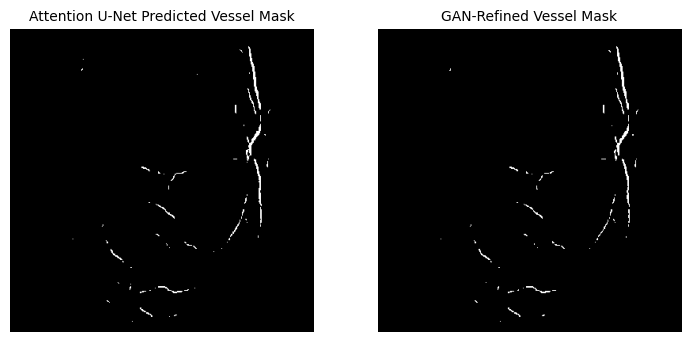


Vessel-mask-only classification results:


,Model,Actual DR,Predicted DR,Prediction Score,Actual-Class Score,Correct
0,B3_predicted,no_dr,no_dr,0.5557,0.5557,Yes
1,B4_refined,no_dr,no_dr,0.4264,0.4264,Yes
2,B4_predicted,no_dr,no_dr,0.3823,0.3823,Yes
3,B3_refined,no_dr,no_dr,0.7818,0.7818,Yes


       Model Actual DR Predicted DR Prediction Score Actual-Class Score Correct
B3_predicted     no_dr        no_dr           0.5557             0.5557     Yes
  B4_refined     no_dr        no_dr           0.4264             0.4264     Yes
B4_predicted     no_dr        no_dr           0.3823             0.3823     Yes
  B3_refined     no_dr        no_dr           0.7818             0.7818     Yes

---------------------------------------------------------------------------------------------------------
Actual DR Severity: mild
Image ID: 10085_left


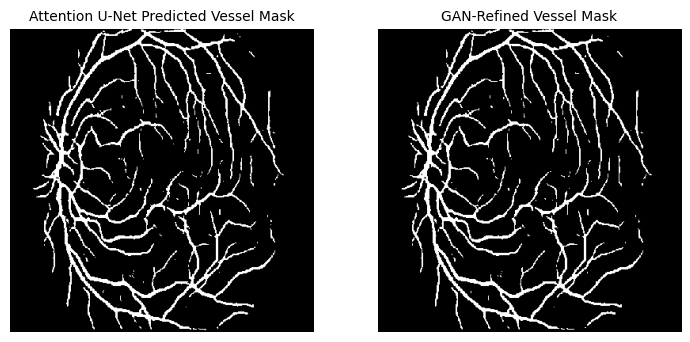


Vessel-mask-only classification results:


,Model,Actual DR,Predicted DR,Prediction Score,Actual-Class Score,Correct
0,B3_predicted,mild,no_dr,0.6248,0.2437,No
1,B4_refined,mild,no_dr,0.5766,0.2977,No
2,B4_predicted,mild,no_dr,0.6109,0.1913,No
3,B3_refined,mild,no_dr,0.6963,0.1148,No


       Model Actual DR Predicted DR Prediction Score Actual-Class Score Correct
B3_predicted      mild        no_dr           0.6248             0.2437      No
  B4_refined      mild        no_dr           0.5766             0.2977      No
B4_predicted      mild        no_dr           0.6109             0.1913      No
  B3_refined      mild        no_dr           0.6963             0.1148      No

---------------------------------------------------------------------------------------------------------
Actual DR Severity: moderate
Image ID: 15594_right


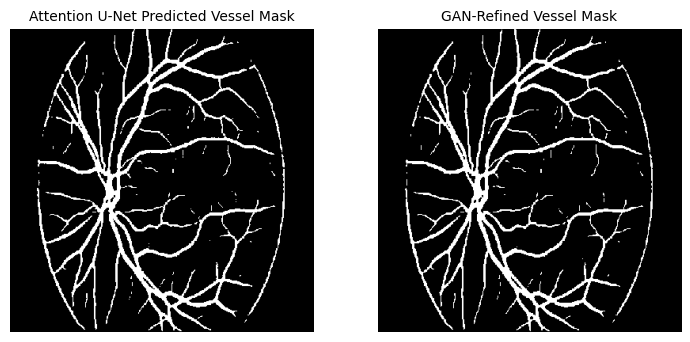


Vessel-mask-only classification results:


,Model,Actual DR,Predicted DR,Prediction Score,Actual-Class Score,Correct
0,B3_predicted,moderate,no_dr,0.3655,0.3374,No
1,B4_refined,moderate,no_dr,0.8427,0.1066,No
2,B4_predicted,moderate,no_dr,0.4188,0.3158,No
3,B3_refined,moderate,no_dr,0.4463,0.3493,No


       Model Actual DR Predicted DR Prediction Score Actual-Class Score Correct
B3_predicted  moderate        no_dr           0.3655             0.3374      No
  B4_refined  moderate        no_dr           0.8427             0.1066      No
B4_predicted  moderate        no_dr           0.4188             0.3158      No
  B3_refined  moderate        no_dr           0.4463             0.3493      No

---------------------------------------------------------------------------------------------------------
Actual DR Severity: severe
Image ID: 10510_left


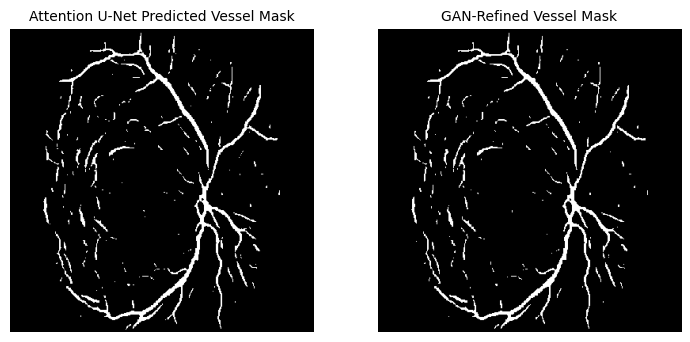


Vessel-mask-only classification results:


,Model,Actual DR,Predicted DR,Prediction Score,Actual-Class Score,Correct
0,B3_predicted,severe,proliferative_dr,0.9831,0.0131,No
1,B4_refined,severe,proliferative_dr,0.9059,0.0692,No
2,B4_predicted,severe,proliferative_dr,0.9845,0.0059,No
3,B3_refined,severe,proliferative_dr,0.9945,0.0024,No


       Model Actual DR     Predicted DR Prediction Score Actual-Class Score Correct
B3_predicted    severe proliferative_dr           0.9831             0.0131      No
  B4_refined    severe proliferative_dr           0.9059             0.0692      No
B4_predicted    severe proliferative_dr           0.9845             0.0059      No
  B3_refined    severe proliferative_dr           0.9945             0.0024      No

---------------------------------------------------------------------------------------------------------
Actual DR Severity: proliferative_dr
Image ID: 10312_left


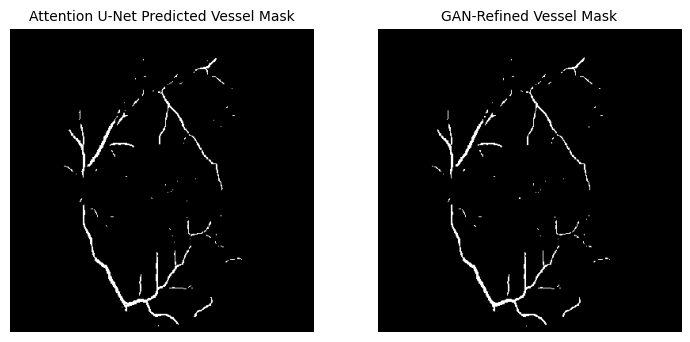


Vessel-mask-only classification results:


,Model,Actual DR,Predicted DR,Prediction Score,Actual-Class Score,Correct
0,B3_predicted,proliferative_dr,proliferative_dr,0.9705,0.9705,Yes
1,B4_refined,proliferative_dr,proliferative_dr,0.4992,0.4992,Yes
2,B4_predicted,proliferative_dr,proliferative_dr,0.4849,0.4849,Yes
3,B3_refined,proliferative_dr,proliferative_dr,0.5422,0.5422,Yes


       Model        Actual DR     Predicted DR Prediction Score Actual-Class Score Correct
B3_predicted proliferative_dr proliferative_dr           0.9705             0.9705     Yes
  B4_refined proliferative_dr proliferative_dr           0.4992             0.4992     Yes
B4_predicted proliferative_dr proliferative_dr           0.4849             0.4849     Yes
  B3_refined proliferative_dr proliferative_dr           0.5422             0.5422     Yes

Final scores and five DR severity comparisons completed.
Prediction records saved to Google Drive: /content/drive/MyDrive/DR_Project/vessel_mask_only_B3_B4_four_models/four_model_example_predictions_one_per_severity.csv
All-image scores and severity averages remain in: /content/drive/MyDrive/DR_Project/vessel_mask_only_B3_B4_four_models/Vessel_Only_B3_B4_Four_Models_Results.xlsx


In [ ]:

from IPython.display import display
from pathlib import Path
import numpy as np

average_tables = []
example_predictions = []

# ============================================================
# AVERAGE ACTUAL-CLASS PREDICTION SCORES
# ============================================================

for exp, backbone, mask_type in EXPERIMENTS:
    folder = OUTPUT_DIR / exp

    av_path = folder / 'test_severity_average_actual_class_scores.csv'
    pred_path = folder / 'test_image_probabilities.csv'

    if not av_path.is_file() or not pred_path.is_file():
        raise FileNotFoundError(
            f'Missing saved test results for {exp}: {folder}'
        )

    av_df = pd.read_csv(av_path)
    av_df['Experiment'] = exp
    average_tables.append(av_df)

all_averages = pd.concat(average_tables, ignore_index=True)

final_averages = (
    all_averages.pivot(
        index='DR-Severity',
        columns='Experiment',
        values='Average-Actual-Class-Score'
    )
    .reindex(CLASS_NAMES)[
        [name for name, _, _ in EXPERIMENTS]
    ]
)

final_averages.index.name = 'DR Severity'

print('\n' + '=' * 105)
print(
    'AVERAGE ACTUAL-CLASS PREDICTION SCORES '
    '- VESSEL MASK ONLY (5 DR SEVERITIES x 4 MODELS)'
)
print('=' * 105)

print(
    final_averages.to_string(
        float_format=lambda value: f'{value:.4f}'
    )
)

print(
    '\nEach average uses all test images whose dataset '
    'label is the indicated DR severity.'
)
print(
    'These are probabilities of the actual class, '
    'not classification accuracy.'
)

# ============================================================
# SELECT ONE IMAGE FOR EACH DR SEVERITY
# ============================================================

examples = (
    FRAMES['test']
    .sort_values('filename')
    .groupby('label', as_index=False, sort=True)
    .first()
)

if set(examples['label'].astype(int)) != set(range(NUM_CLASSES)):
    raise RuntimeError(
        'Could not select one test image for each DR class.'
    )

# ============================================================
# SELECT A MODERATE IMAGE WITH VISIBLE VESSELS
# ============================================================

def vessel_fraction(mask_path):

    with Image.open(str(mask_path)) as image:
        mask = np.asarray(
            image.convert('L').resize(
                (IMG_SIZE, IMG_SIZE),
                Image.Resampling.NEAREST
            )
        )

    threshold = 0 if mask.max() <= 1 else 127

    return float(np.mean(mask > threshold))


moderate_id = next(
    (
        i for i, name in enumerate(CLASS_NAMES)
        if str(name).strip().lower() == 'moderate'
    ),
    None
)

if moderate_id is None:
    raise RuntimeError('Moderate DR class not found.')

moderate_candidates = FRAMES['test'].loc[
    FRAMES['test']['label'].astype(int).eq(moderate_id)
].copy()

best_moderate = None
best_score = -1.0

for _, candidate in moderate_candidates.iterrows():

    predicted_path = Path(str(candidate['predicted_mask']))
    refined_path = Path(str(candidate['refined_mask']))

    if not predicted_path.is_file() or not refined_path.is_file():
        continue

    predicted_fraction = vessel_fraction(predicted_path)
    refined_fraction = vessel_fraction(refined_path)


    if not (
        0.03 <= predicted_fraction <= 0.30
        and 0.03 <= refined_fraction <= 0.30
    ):
        continue


    score = min(predicted_fraction, refined_fraction)

    if score > best_score:
        best_score = score
        best_moderate = candidate

if best_moderate is None:
    raise RuntimeError(
        'No Moderate DR test image met the vessel visibility '
        'criteria. Check the saved predicted and refined masks.'
    )


examples.loc[
    examples['label'].astype(int).eq(moderate_id),
    examples.columns
] = best_moderate[examples.columns].values


model_output = {}

for exp, backbone, mask_type in EXPERIMENTS:

    prediction_df = pd.read_csv(
        OUTPUT_DIR / exp / 'test_image_probabilities.csv'
    )

    if prediction_df['Filename'].duplicated().any():
        raise RuntimeError(
            f'Duplicate test predictions for model {exp}.'
        )

    model_output[exp] = prediction_df.set_index('Filename')



for severity_id, severity in enumerate(CLASS_NAMES):

    item = examples.loc[
        examples['label'].astype(int).eq(severity_id)
    ].iloc[0]

    filename = str(item['filename'])
    image_id = Path(filename).stem

    print('\n' + '-' * 105)
    print(f'Actual DR Severity: {severity}')
    print(f'Image ID: {image_id}')

    # Display ONLY vessel masks.
    fig, axes = plt.subplots(
        1, 2,
        figsize=(7.5, 3.5)
    )

    mask_columns = [
        'predicted_mask',
        'refined_mask'
    ]

    mask_titles = [
        'Attention U-Net Predicted Vessel Mask',
        'GAN-Refined Vessel Mask'
    ]

    for ax, mask_col, title in zip(
        axes,
        mask_columns,
        mask_titles
    ):

        with Image.open(str(item[mask_col])) as image:
            vessel_mask = image.convert('L').resize(
                (IMG_SIZE, IMG_SIZE),
                Image.Resampling.NEAREST
            )

            ax.imshow(
                vessel_mask,
                cmap='gray',
                vmin=0,
                vmax=255
            )

        ax.set_title(title, fontsize=10)
        ax.axis('off')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    sample_rows = []

    for exp, backbone, mask_type in EXPERIMENTS:

        if filename not in model_output[exp].index:
            raise RuntimeError(
                f'Missing prediction for {filename} in {exp}.'
            )

        pred = model_output[exp].loc[filename]

        predicted_severity = str(
            pred['Predicted-Severity']
        )

        predicted_score = float(
            pred['Prob-' + predicted_severity]
        )

        actual_score = float(
            pred['Actual-Class-Score']
        )

        sample_rows.append({
            'Model': exp,
            'Actual DR': severity,
            'Predicted DR': predicted_severity,
            'Prediction Score': predicted_score,
            'Actual-Class Score': actual_score,
            'Correct': (
                'Yes'
                if predicted_severity == severity
                else 'No'
            )
        })

        example_predictions.append({
            'Filename': filename,
            'Vessel-Mask-Only Model': exp,
            'Mask Type': mask_type,
            **sample_rows[-1]
        })

    sample_df = pd.DataFrame(sample_rows)

    print('\nVessel-mask-only classification results:')

    display(
        sample_df.style.format({
            'Prediction Score': '{:.4f}',
            'Actual-Class Score': '{:.4f}'
        })
    )

    print(
        sample_df.to_string(
            index=False,
            formatters={
                'Prediction Score': lambda x: f'{x:.4f}',
                'Actual-Class Score': lambda x: f'{x:.4f}'
            }
        )
    )



example_csv = (
    OUTPUT_DIR /
    'four_model_example_predictions_one_per_severity.csv'
)

pd.DataFrame(example_predictions).to_csv(
    example_csv,
    index=False,
    float_format='%.8f'
)

print('\n' + '=' * 105)
print('Final scores and five DR severity comparisons completed.')
print('Prediction records saved to Google Drive:', example_csv)
print(
    'All-image scores and severity averages remain in:',
    OUTPUT_DIR / 'Vessel_Only_B3_B4_Four_Models_Results.xlsx'
)
